# Przebieg v2 a zamrożony przebieg

**Porównywane przebiegi.** Oba na Gemmie 4 12B, na tej samej populacji (43 991 wypowiedzi).

| | tematyczność | twierdzenia | werdykt | wyszukiwanie AR6 |
|---|---|---|---|---|
| zamrożony (15.10) | `topic_v0` | `claims_v1` | `verdict_v1` | RRF: bge-m3 PL + EN + BM25 |
| v2 (05.11) | `topic_v1` | `claims_v2` | `verdict_v2` | embeddinggemma:300m, EN |

**Grupy.** W v2 Kukiz15 (od 04.11) i Republikanie (od 05.11) należą do prawicy (decyzje leada). Etykiety zamrożonego przebiegu są tu przeliczone na
nowe grupy, żeby różnice wynikały tylko z pipeline'u. Wyjątek: stary gold (sekcja 5) ma warstwy i wagi z zamrożonego
przebiegu i stare grupy; nowy gold (sekcja 6) ma warstwy, wagi i grupy z v2.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from amc import annotation, estimation, viz
from amc.viz import ACCENT, SECOND, SURF

viz.setup()
pd.set_option("display.width", 200)

LABEL_DIR = ROOT / "data" / "processed" / "labels"
GROUPS = estimation.GROUPS
VERDICTS = ["brak_podstaw", "zgodne", "sprzeczne"]
RUNS = {
    "zamrożony": ("gemma4_12b.csv", "gemma4_12b_claims.csv"),
    "v2": ("gemma4_12b__verdict_v2__en_embeddinggemma_300m.csv",
           "gemma4_12b__verdict_v2__en_embeddinggemma_300m_claims.csv"),
}
COLORS = {"zamrożony": ACCENT, "v2": SECOND}

labels = {run: pd.read_csv(LABEL_DIR / files[0]) for run, files in RUNS.items()}
claims = {run: pd.read_csv(LABEL_DIR / files[1]) for run, files in RUNS.items()}
assert (labels["zamrożony"]["wypowiedz_id"] == labels["v2"]["wypowiedz_id"]).all()
labels["zamrożony"]["grupa"] = labels["v2"]["grupa"]

## 1. Tematyczność

In [2]:
rows = {}
for run, run_labels in labels.items():
    topical = run_labels[run_labels["klimat"] == 1]
    rows[run] = topical.groupby("grupa").size().reindex(GROUPS).to_dict() | {"razem": len(topical)}
pd.DataFrame.from_dict(rows, orient="index")

,prawica,reszta,razem
zamrożony,932,713,1645
v2,926,849,1775


In [3]:
pd.crosstab(labels["zamrożony"]["klimat"], labels["v2"]["klimat"],
            rownames=["zamrożony (topic_v0)"], colnames=["v2 (topic_v1)"], margins=True, margins_name="razem")

v2 (topic_v1),0,1,razem
zamrożony (topic_v0),,,
0,41616,730,42346
1,600,1045,1645
razem,42216,1775,43991


## 2. Twierdzenia

Liczone tylko dla wypowiedzi tematycznych w danym przebiegu.

In [4]:
rows = {}
for run, run_labels in labels.items():
    topical = run_labels[run_labels["klimat"] == 1]
    per_statement = topical["wypowiedz_id"].map(claims[run]["wypowiedz_id"].value_counts()).fillna(0)
    rows[run] = {
        "twierdzenia": len(claims[run]),
        "na wypowiedź (średnia)": per_statement.mean(),
        "na wypowiedź (mediana)": per_statement.median(),
        "wypowiedzi bez twierdzeń": int((per_statement == 0).sum()),
    }
pd.DataFrame.from_dict(rows, orient="index").round(2)

,twierdzenia,na wypowiedź (średnia),na wypowiedź (mediana),wypowiedzi bez twierdzeń
zamrożony,1636,0.99,0.0,885
v2,6872,3.87,3.0,67


## 3. Werdykty

Udział werdyktów wśród twierdzeń i źródło w AR6 (grupa robocza) dla werdyktów `sprzeczne`.

In [5]:
rows = {}
for run, run_claims in claims.items():
    counts = run_claims["werdykt"].value_counts().reindex(VERDICTS, fill_value=0)
    rows[run] = {f"{verdict} %": 100 * n / counts.sum() for verdict, n in counts.items()}
pd.DataFrame.from_dict(rows, orient="index").round(1)

,brak_podstaw %,zgodne %,sprzeczne %
zamrożony,69.4,24.1,6.4
v2,86.1,8.3,5.7


In [6]:
def working_group(ar6):
    return ar6.split()[0] if isinstance(ar6, str) and ar6 else "brak"


rows = {}
for run, run_claims in claims.items():
    contradicting = run_claims[run_claims["werdykt"] == "sprzeczne"]
    rows[run] = contradicting["ar6"].map(working_group).value_counts()
pd.DataFrame(rows).fillna(0).astype(int).T

ar6,WGIII,WGI,WGII
zamrożony,59,33,13
v2,335,33,23


In [7]:
TOP_SECTIONS = 5
for run, run_claims in claims.items():
    contradicting = run_claims[run_claims["werdykt"] == "sprzeczne"]
    sections = contradicting["ar6"].str.replace(r" \(s\. \d+\)", "", regex=True)
    print(run, f"({len(contradicting)} sprzecznych)")
    print(sections.value_counts().head(TOP_SECTIONS).to_string(), end="\n\n")

zamrożony (105 sprzecznych)
ar6
WGIII TS TS.5.1    18
WGIII SPM C.4.3     7
WGII SPM D.5.3      6
WGI SPM B.1         5
WGIII TS TS.3       5

v2 (391 sprzecznych)
ar6
WGIII TS TS.5.1    98
WGIII SPM B.4.1    27
WGIII TS TS.5.5    21
WGIII SPM C.4.3    20
WGIII TS TS.2      17



## 4. Wypowiedzi sprzeczne według modelu

Wypowiedź sprzeczna = wypowiedź tematyczna z co najmniej jednym twierdzeniem `sprzeczne`; odsetek wśród tematycznych
w grupie. β1 z regresji logistycznej (krok 6, błędy grupowane po mówcy) z 95% przedziałem.

In [8]:
rows = {}
for run, run_labels in labels.items():
    shares = estimation.raw_shares(run_labels)
    fit = estimation.regression(run_labels)
    row = {group: f"{int(shares.loc[group, 'sprzeczne'])}/{int(shares.loc[group, 'tematyczne'])} "
                  f"({100 * shares.loc[group, 'odsetek']:.1f}%)" for group in GROUPS}
    row["różnica pp"] = 100 * (shares.loc["prawica", "odsetek"] - shares.loc["reszta", "odsetek"])
    row["β1 [95% CI]"] = (f"{fit['beta1']:.2f} [{fit['beta1'] - 1.96 * fit['se']:.2f}; "
                          f"{fit['beta1'] + 1.96 * fit['se']:.2f}]")
    row["p jednostronne"] = fit["p_jednostronne"]
    rows[run] = row
group_table = pd.DataFrame.from_dict(rows, orient="index")
group_table.round({"różnica pp": 1, "p jednostronne": 4})

,prawica,reszta,różnica pp,β1 [95% CI],p jednostronne
zamrożony,63/932 (6.8%),25/713 (3.5%),3.3,0.69 [0.21; 1.17],0.0026
v2,231/926 (24.9%),86/849 (10.1%),14.8,1.08 [0.80; 1.37],0.0000


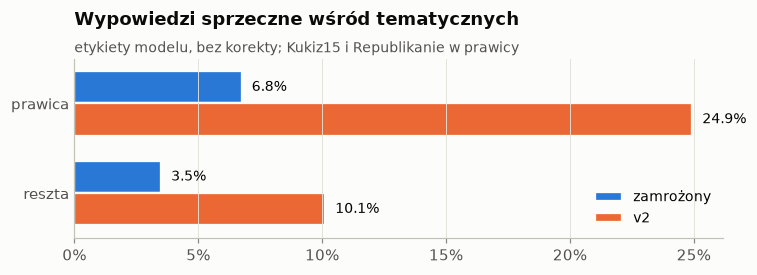

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
bar_height = 0.36
for offset, run in zip((-bar_height / 2, bar_height / 2), labels):
    shares = 100 * estimation.raw_shares(labels[run])["odsetek"]
    positions = np.arange(len(GROUPS)) + offset
    ax.barh(positions, shares, height=bar_height, color=COLORS[run], edgecolor=SURF, linewidth=1.5, label=run)
    for position, share in zip(positions, shares):
        ax.text(share + 0.4, position, f"{share:.1f}%", va="center", fontsize=9)
ax.set_yticks(range(len(GROUPS)), GROUPS)
ax.set_ylim(len(GROUPS) - 0.5, -0.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:g}%"))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Wypowiedzi sprzeczne wśród tematycznych")
viz.subtitle(ax, "etykiety modelu, bez korekty; Kukiz15 i Republikanie w prawicy")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

Zmiany etykiety między przebiegami wśród wypowiedzi tematycznych w obu.

In [10]:
both_topical = (labels["zamrożony"]["klimat"] == 1) & (labels["v2"]["klimat"] == 1)
pd.crosstab([labels["v2"]["grupa"][both_topical], labels["zamrożony"]["sprzeczna"][both_topical]],
            labels["v2"]["sprzeczna"][both_topical], rownames=["grupa", "zamrożony"], colnames=["v2"])

v2                 0.0  1.0
grupa   zamrożony          
prawica 0.0        414  109
        1.0         15   47
reszta  0.0        393   45
        1.0         12   10

## 5. Stary gold (orientacyjnie)

Gold z repo (100 wypowiedzi, anotacje FP i DK) oznaczano według codebooka sprzed 04.11, a warstwy wylosowano
z zamrożonego przebiegu, więc porównanie faworyzuje zamrożony przebieg. Miary z wagami warstw (estymator
Horvitza–Thompsona, poprawny dla dowolnej etykiety modelu); grupy jak w próbie (Kukiz15 i Republikanie w reszcie). #94 po korekcie
(1/0, commit `54d8732`). Bez przedziałów: przy kilkunastu sprzecznych w goldzie są szerokie.

In [11]:
design = pd.read_csv(ROOT / "data" / "gold" / "sample.csv")
annotation_files = [ROOT / "data" / "gold" / f"annotations_{initials}.csv" for initials in ("FP", "DK")]
annotations = annotation.load_parts(annotation_files, design)[["kolejnosc", "tematyczna", "sprzeczna"]]
gold = design.merge(annotations, on="kolejnosc")
gold_arrays = estimation.arrays(gold)

def run_quality(gold, gold_arrays):
    gold_contradicting = gold_arrays["s"].astype(bool)
    rows = {}
    for run, run_labels in labels.items():
        in_sample = run_labels.set_index("wypowiedz_id").loc[gold["wypowiedz_id"]]
        model_topical = in_sample["klimat"].to_numpy(int)
        model_contradicting = (model_topical * in_sample["sprzeczna"].fillna(0).to_numpy(int))
        quality = estimation.quality({**gold_arrays, "mt": model_topical, "ms": model_contradicting})
        row = {
            "model": int(model_contradicting.sum()),
            "TP": int((model_contradicting.astype(bool) & gold_contradicting).sum()),
            "FP": int((model_contradicting.astype(bool) & ~gold_contradicting).sum()),
            "FN": int((~model_contradicting.astype(bool) & gold_contradicting).sum()),
        }
        for group in GROUPS:
            row[f"{group} tematyczność precyzja"] = quality[f"{group}_tematycznosc_precyzja"]
            row[f"{group} tematyczność czułość"] = quality[f"{group}_tematycznosc_TPR"]
            row[f"{group} sprzeczność precyzja"] = quality[f"{group}_etykieta_precyzja"]
            row[f"{group} sprzeczność czułość"] = quality[f"{group}_etykieta_TPR"]
        rows[run] = row
    return pd.DataFrame.from_dict(rows, orient="index").round(2).T


run_quality(gold, gold_arrays)

,zamrożony,v2
model,40.00,28.00
TP,14.00,14.00
FP,26.00,14.00
FN,2.00,2.00
prawica tematyczność precyzja,0.30,0.48
prawica tematyczność czułość,1.00,1.00
prawica sprzeczność precyzja,0.60,0.56
prawica sprzeczność czułość,0.25,0.60
reszta tematyczność precyzja,0.34,0.13
reszta tematyczność czułość,1.00,1.00


## 6. Nowy gold z warstw v2 (anotacja Opusa)

Próba 100 wypowiedzi wylosowana z etykiet v2 (ziarno 0, grupy jak w v2), oznaczona przez Claude Opus według zamrożonej instrukcji `data/gold/opus/instrukcja.md` (1 przebieg). **To nie jest gold ludzki**: dopóki etykiety nie zostaną zweryfikowane ręcznie, wyniki tej sekcji i sekcji 7 są wstępne.

In [12]:
import json

V2_GOLD = ROOT / "data" / "gold" / "v2"
design_v2 = pd.read_csv(V2_GOLD / "sample.csv")
drawn = design_v2.groupby(["grupa", "warstwa"])["N_h"].first()
assert drawn.equals(estimation.strata_sizes(labels["v2"]).set_index(["grupa", "warstwa"])["N_h"].reindex(drawn.index))

opus = pd.DataFrame([json.loads(line) for f in sorted((V2_GOLD / "opus" / "out").glob("run1_*.jsonl"))
                     for line in open(f, encoding="utf-8") if line.strip()])
assert sorted(opus["kolejnosc"]) == sorted(design_v2["kolejnosc"])
gold_v2 = design_v2.merge(opus[["kolejnosc", "tematyczna", "sprzeczna", "pewnosc"]], on="kolejnosc")
gold_v2_arrays = estimation.arrays(gold_v2)

composition = estimation.composition(gold_v2)
composition["niska pewność"] = gold_v2.groupby(["grupa", "warstwa"])["pewnosc"].apply(lambda p: int((p == "niska").sum())).to_numpy()
composition["precyzja modelu"] = np.where(composition["warstwa"] == 1,
                                          composition["sprzeczne"] / composition["n_h"], np.nan)
composition.round(2)

,grupa,warstwa,N_h,n_h,waga,tematyczne,sprzeczne,niska pewność,precyzja modelu
0,prawica,1,231,20,11.55,18,8,12,0.4
1,prawica,2,695,15,46.33,10,0,5,NaN
2,prawica,3,20266,15,1351.07,0,0,0,NaN
3,reszta,1,86,20,4.30,16,2,8,0.1
4,reszta,2,763,15,50.87,10,0,5,NaN
5,reszta,3,21950,15,1463.33,0,0,0,NaN


Jakość obu przebiegów na nowym golu (wagi warstw v2, estymator Horvitza–Thompsona). Tym razem próba pochodzi z v2, więc porównanie faworyzuje v2 (odwrotnie niż w sekcji 5).

In [13]:
run_quality(gold_v2, gold_v2_arrays)

,zamrożony,v2
model,9.00,40.00
TP,1.00,10.00
FP,8.00,30.00
FN,9.00,0.00
prawica tematyczność precyzja,0.90,0.72
prawica tematyczność czułość,0.64,1.00
prawica sprzeczność precyzja,0.17,0.40
prawica sprzeczność czułość,0.13,1.00
reszta tematyczność precyzja,0.48,0.68
reszta tematyczność czułość,0.34,1.00


## 7. Test hipotezy (krok 7)

p_g = Σ w·s / Σ w·t z etykiet golda w grupie g, różnica prawica − reszta, bootstrap warstwowy (10 000 powtórzeń, losowanie ze zwracaniem w komórkach grupa × warstwa, wagi stałe). Hipoteza poparta, gdy jednostronna dolna granica 95% (5. percentyl) różnicy > 0. Krok 7 zależy tylko od golda, więc liczę go dla każdej próby, nie dla każdego przebiegu.

In [14]:
REPS = 10_000
golds = {"stary gold (zamrożony, FP+DK)": gold, "nowy gold (v2, Opus)": gold_v2}
step7 = {}
for name, sample in golds.items():
    summary = estimation.summarize(sample, estimation.proportions, reps=REPS)
    step7[name] = summary
    print(name)
    display((100 * summary.drop(columns="bootstrap_brak")).round(1).join(summary["bootstrap_brak"]))

verdicts = pd.DataFrame({name: {
    "różnica pp": round(100 * s.loc["roznica", "wartosc"], 1),
    "dolna 95% jedn. pp": round(100 * s.loc["roznica", "dolna_95_jednostronna"], 1),
    "hipoteza": "poparta" if s.loc["roznica", "dolna_95_jednostronna"] > 0 else "niepoparta",
} for name, s in step7.items()}).T
verdicts

stary gold (zamrożony, FP+DK)


,wartosc,dolna_95_jednostronna,przedzial_2.5,przedzial_97.5,bootstrap_brak
p_prawica,55.1,19.7,15.2,97.2,0
p_reszta,1.1,0.0,0.0,4.2,0
roznica,54.0,18.2,13.8,96.0,0


nowy gold (v2, Opus)


,wartosc,dolna_95_jednostronna,przedzial_2.5,przedzial_97.5,bootstrap_brak
p_prawica,13.8,7.6,6.4,23.2,0
p_reszta,1.5,0.0,0.0,4.0,0
roznica,12.3,5.8,4.6,21.7,0


,różnica pp,dolna 95% jedn. pp,hipoteza
"stary gold (zamrożony, FP+DK)",54.0,18.2,poparta
"nowy gold (v2, Opus)",12.3,5.8,poparta


Rozkład bootstrapowy różnicy na nowym golu.

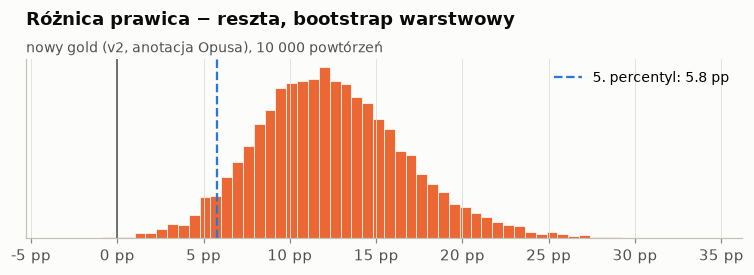

In [15]:
boot = estimation.bootstrap(gold_v2, estimation.proportions, reps=REPS)
lower = boot["roznica"].quantile(0.05)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(100 * boot["roznica"].dropna(), bins=60, color=SECOND, edgecolor=SURF, linewidth=0.5)
ax.axvline(0, color="0.3", linewidth=1)
ax.axvline(100 * lower, color=ACCENT, linewidth=1.5, linestyle="--", label=f"5. percentyl: {100 * lower:.1f} pp")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:g} pp"))
ax.set_yticks([])
ax.set_title("Różnica prawica − reszta, bootstrap warstwowy")
viz.subtitle(ax, "nowy gold (v2, anotacja Opusa), 10 000 powtórzeń")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

Wrażliwość na etykiety Opusa z niską pewnością: wypowiedzi sprzeczne z `pewnosc = niska` zamienione na niesprzeczne (wariant ostrożny wobec hipotezy, bo prawie wszystkie sprzeczne są w warstwie 1 prawicy).

In [16]:
strict = gold_v2.copy()
low_contradicting = (strict["pewnosc"] == "niska") & (strict["sprzeczna"] == 1)
print(f"zamienione: {int(low_contradicting.sum())} "
      f"({strict.loc[low_contradicting, 'grupa'].value_counts().to_dict()})")
strict.loc[low_contradicting, "sprzeczna"] = 0
(100 * estimation.summarize(strict, estimation.proportions, reps=REPS).drop(columns="bootstrap_brak")).round(1)

zamienione: 8 ({'prawica': 6, 'reszta': 2})


,wartosc,dolna_95_jednostronna,przedzial_2.5,przedzial_97.5
p_prawica,3.4,0.0,0.0,9.1
p_reszta,0.0,0.0,0.0,0.0
roznica,3.4,0.0,0.0,9.1


## 8. Połączony gold: obie próby z etykietami Opusa

Stary gold oznaczony przez Opusa tą samą zamrożoną instrukcją co nowy (`data/gold/opus/out`, przebieg 1), więc obie
próby mają etykiety według codebooka z 04.11 od jednego anotatora. Próby są niezależnymi losowaniami z tej samej
populacji, każda z własnym schematem warstw:

- każda próba daje estymator Horvitza–Thompsona sum Σ w·s i Σ w·t w grupie, nieobciążony przy wagach swojego
  schematu; grupa jest tu tylko domeną, więc grupy v2 (Kukiz15 i Republikanie w prawicy) można przypisać także
  wypowiedziom starej próby, mimo że losowano ją w starych grupach;
- połączony estymator = średnia sum z obu prób (wagi 1/2, obie po 100 wypowiedzi), potem p_g = S_g / T_g;
- bootstrap niezależnie w każdej próbie, ze zwracaniem w komórkach jej własnego losowania (grupa × warstwa z chwili
  losowania).

8 wypowiedzi jest w obu próbach; przy niezależnych losowaniach to dopuszczalne.

In [17]:
def opus_labels(out_dir):
    return pd.DataFrame([json.loads(line) for f in sorted(Path(out_dir).glob("run1_*.jsonl"))
                         for line in open(f, encoding="utf-8") if line.strip()])


def opus_sample(design, out_dir):
    sample = design.merge(opus_labels(out_dir)[["kolejnosc", "tematyczna", "sprzeczna", "pewnosc"]],
                          on="kolejnosc", validate="1:1")
    sample["komorka"] = sample["grupa"] + "_" + sample["warstwa"].astype(str)
    sample["grupa"] = sample["wypowiedz_id"].map(labels["v2"].set_index("wypowiedz_id")["grupa"])
    sample["t"] = sample["tematyczna"].astype(int)
    sample["s"] = sample["t"] * sample["sprzeczna"].fillna(0).astype(int)
    return sample


opus_golds = {"stary": opus_sample(design, ROOT / "data" / "gold" / "opus" / "out"),
              "nowy": opus_sample(design_v2, V2_GOLD / "opus" / "out")}
pd.DataFrame({name: {"wypowiedzi": len(d), "tematyczne": d["t"].sum(), "sprzeczne": d["s"].sum(),
                     "sprzeczne z niską pewnością": ((d["s"] == 1) & (d["pewnosc"] == "niska")).sum(),
                     "zmiana grupy na v2": (d["grupa"] != d["komorka"].str.split("_").str[0]).sum()}
              for name, d in opus_golds.items()}).T

,wypowiedzi,tematyczne,sprzeczne,sprzeczne z niską pewnością,zmiana grupy na v2
stary,100,50,11,3,3
nowy,100,54,10,8,0


Zgodność Opusa z FP/DK na starej próbie (etykieta końcowa: tematyczna i sprzeczna).

In [18]:
human = gold.set_index("kolejnosc")
human_label = (human["tematyczna"] * human["sprzeczna"].fillna(0)).astype(int).rename("FP/DK")
opus_label = opus_golds["stary"].set_index("kolejnosc")["s"].rename("Opus")
pd.crosstab(human_label, opus_label.reindex(human_label.index), margins=True, margins_name="razem")

Opus,0,1,razem
FP/DK,,,
0,84,0,84
1,5,11,16
razem,89,11,100


In [19]:
def prepare(sample):
    cell = sample["komorka"].to_numpy()
    return {"w": sample["waga"].to_numpy(float), "s": sample["s"].to_numpy(int), "t": sample["t"].to_numpy(int),
            "g": sample["grupa"].to_numpy(), "cells": [np.flatnonzero(cell == c) for c in sorted(set(cell))]}


def combined_proportions(parts, indices=None):
    contradicting, topical = dict.fromkeys(GROUPS, 0.0), dict.fromkeys(GROUPS, 0.0)
    for k, part in enumerate(parts):
        idx = slice(None) if indices is None else indices[k]
        w, s, t, g = part["w"][idx], part["s"][idx], part["t"][idx], part["g"][idx]
        for group in GROUPS:
            in_group = g == group
            contradicting[group] += (w * s)[in_group].sum() / len(parts)
            topical[group] += (w * t)[in_group].sum() / len(parts)
    out = {f"p_{group}": contradicting[group] / topical[group] if topical[group] else np.nan for group in GROUPS}
    out["roznica"] = out["p_prawica"] - out["p_reszta"]
    return out


def combined_summary(samples, reps=REPS, seed=2026):
    parts = [prepare(sample) for sample in samples]
    rng = np.random.default_rng(seed)
    boot = pd.DataFrame([
        combined_proportions(parts, [np.concatenate([c[rng.integers(0, len(c), len(c))] for c in part["cells"]])
                                     for part in parts])
        for _ in range(reps)])
    return pd.DataFrame({"wartosc": pd.Series(combined_proportions(parts)),
                         "dolna_95_jednostronna": boot.quantile(0.05), "przedzial_2.5": boot.quantile(0.025),
                         "przedzial_97.5": boot.quantile(0.975)})


def without_low_confidence(sample):
    sample = sample.copy()
    sample.loc[(sample["pewnosc"] == "niska") & (sample["s"] == 1), "s"] = 0
    return sample


def verdict_table(summaries):
    return pd.DataFrame({name: {
        "p prawica %": round(100 * s.loc["p_prawica", "wartosc"], 1),
        "p reszta %": round(100 * s.loc["p_reszta", "wartosc"], 1),
        "różnica pp": round(100 * s.loc["roznica", "wartosc"], 1),
        "dolna 95% jedn. pp": round(100 * s.loc["roznica", "dolna_95_jednostronna"], 1),
        "przedział 95% pp": f"[{100 * s.loc['roznica', 'przedzial_2.5']:.1f}; "
                            f"{100 * s.loc['roznica', 'przedzial_97.5']:.1f}]",
        "hipoteza": "poparta" if s.loc["roznica", "dolna_95_jednostronna"] > 0 else "niepoparta",
    } for name, s in summaries.items()}).T


variants = {
    "stary (Opus)": [opus_golds["stary"]],
    "nowy (Opus)": [opus_golds["nowy"]],
    "połączony": list(opus_golds.values()),
    "połączony, niska pewność → 0": [without_low_confidence(d) for d in opus_golds.values()],
}
combined = {name: combined_summary(samples) for name, samples in variants.items()}
verdict_table(combined)

,p prawica %,p reszta %,różnica pp,dolna 95% jedn. pp,przedział 95% pp,hipoteza
stary (Opus),4.5,0.2,4.4,1.7,[1.2; 8.0],poparta
nowy (Opus),13.8,1.5,12.3,5.7,[4.5; 22.0],poparta
połączony,9.4,0.5,8.9,5.0,[4.3; 14.1],poparta
"połączony, niska pewność → 0",3.5,0.1,3.4,1.4,[1.1; 6.7],poparta


Wpływ pojedynczych wypowiedzi na połączony wynik: każda wypowiedź sprzeczna według Opusa po kolei zamieniona na
niesprzeczną (bootstrap 2000 powtórzeń na wariant). Dla porównania: w starym goldzie FP/DK całą decyzję robiła #94.

In [20]:
LOO_REPS = 2_000
rows = []
for name, sample in opus_golds.items():
    for i in sample.index[sample["s"] == 1]:
        flipped = {k: d.copy() for k, d in opus_golds.items()}
        flipped[name].loc[i, "s"] = 0
        s = combined_summary(list(flipped.values()), reps=LOO_REPS)
        rows.append({"próba": name, "kolejnosc": sample.loc[i, "kolejnosc"], "grupa": sample.loc[i, "grupa"],
                     "komórka losowania": sample.loc[i, "komorka"], "waga": sample.loc[i, "waga"],
                     "pewność": sample.loc[i, "pewnosc"], "różnica pp": 100 * s.loc["roznica", "wartosc"],
                     "dolna 95% jedn. pp": 100 * s.loc["roznica", "dolna_95_jednostronna"]})
influence = pd.DataFrame(rows).sort_values("dolna 95% jedn. pp").reset_index(drop=True)
print(f"bez zmian: dolna {100 * combined['połączony'].loc['roznica', 'dolna_95_jednostronna']:.1f} pp; "
      f"najniższa po zamianie jednej: {influence['dolna 95% jedn. pp'].min():.1f} pp; "
      f"warianty z dolną ≤ 0: {(influence['dolna 95% jedn. pp'] <= 0).sum()} z {len(influence)}")
influence.round(1)

bez zmian: dolna 5.0 pp; najniższa po zamianie jednej: 4.2 pp; warianty z dolną ≤ 0: 0 z 21


,próba,kolejnosc,grupa,komórka losowania,waga,pewność,różnica pp,dolna 95% jedn. pp
0,nowy,53,prawica,prawica_1,11.6,wysoka,8.0,4.2
1,nowy,23,prawica,prawica_1,11.6,niska,8.0,4.2
2,nowy,20,prawica,prawica_1,11.6,niska,8.0,4.2
3,nowy,95,prawica,prawica_1,11.6,niska,8.0,4.2
4,nowy,27,prawica,prawica_1,11.6,niska,8.0,4.2
5,nowy,69,prawica,prawica_1,11.6,niska,8.0,4.3
6,nowy,47,prawica,prawica_1,11.6,wysoka,8.0,4.3
7,nowy,71,prawica,prawica_1,11.6,niska,8.0,4.3
8,stary,88,prawica,prawica_1,3.0,wysoka,8.7,4.7
9,stary,95,prawica,prawica_1,3.0,niska,8.7,4.7


## Wnioski

1. **Tematyczność.** `topic_v1` oznacza 1775 wypowiedzi jako tematyczne (zamrożony: 1645), ale przebiegi pokrywają się
   tylko w 1045. v2 dodaje 730 i odrzuca 600, więc zmiana codebooka przesunęła granicę tematyczności, a nie tylko ją
   poszerzyła.
2. **Twierdzenia.** `claims_v2` wyciąga ponad 4 razy więcej twierdzeń (6872 wobec 1636, mediana 3 na wypowiedź), a
   wypowiedzi tematycznych bez twierdzeń jest 67 zamiast 885. Udział werdyktu `sprzeczne` jest podobny (5,7% wobec
   6,4%), ale przez liczbę twierdzeń więcej wypowiedzi ma co najmniej jedno sprzeczne.
3. **Źródło sprzeczności.** W v2 sprzeczność pochodzi prawie wyłącznie z WGIII (335 z 391), głównie z TS.5.1 (koszty
   OZE). To sygnał, że reguła 6b (koszty i wykonalność tylko przy twierdzeniu ogólnym) nie jest w pełni przestrzegana
   przez `verdict_v2`.
4. **Etykiety modelu (krok 6).** Różnica prawica − reszta rośnie z 3,3 do 14,8 pp (β1 0,69 → 1,08, p < 0,001 w obu).
   Kierunek jest zgodny z hipotezą w obu przebiegach, ale to etykiety bez korekty.
5. **Jakość na goldach.** Na starym goldzie v2 ma mniej fałszywych `sprzeczne` (14 wobec 26) przy tej samej liczbie
   trafień (14) i wyższej czułości w prawicy (0,60 wobec 0,25). Na nowym goldzie precyzja v2 w warstwie T∧S jest niska
   (prawica 0,40, reszta 0,10), czyli model nadal mocno przeszacowuje sprzeczność; zamrożony przebieg prawie nie
   znajduje sprzecznych wypowiedzi według nowego golda. Każdy gold faworyzuje przebieg, z którego go wylosowano.
6. **Hipoteza (krok 7).** Na obu goldach poparta: stary 54,0 pp (dolna granica 18,2), nowy 12,3 pp (5,8). Oba wyniki
   są kruche. Na starym całą zmianę robi jedna wypowiedź (#94, waga 48,6); na nowym po zamianie 8 sprzecznych z niską
   pewnością Opusa na niesprzeczne dolna granica spada do 0, a hipoteza przestaje być poparta.
7. **Ograniczenia.** Nowy gold to anotacja modelu (Opus, 1 przebieg), nie ludzi. W warstwie ¬T (15 z ok. 20 tys.
   wypowiedzi na grupę) nie znaleziono żadnej tematycznej, więc bootstrap nie oddaje niepewności co do sprzecznych
   wypowiedzi pominiętych przez model.
8. **Połączony gold (sekcja 8).** Obie próby z etykietami Opusa: różnica 8,9 pp, dolna granica 5,0 → poparta, także po
   zamianie sprzecznych z niską pewnością na 0 (3,4 pp, dolna 1,4). Zamiana dowolnej jednej sprzecznej wypowiedzi
   obniża dolną granicę najwyżej do 4,2 pp, więc wynik nie zależy już od jednej wypowiedzi. Powód: Opus znajduje
   sprzeczne tylko w warstwie T∧S, gdzie wagi są małe (3,0–11,6), a w warstwach z dużymi wagami nie ma żadnej. Na
   starej próbie Opus oznacza jako sprzeczne 11 z 16 wypowiedzi sprzecznych według FP/DK i żadnej innej; odrzuca m.in.
   #36 i #59 z warstwy 2, stąd 4,5% zamiast 55,1% w prawicy. Ta sama uwaga co w punkcie 7: brak sprzecznych w
   warstwach 2 i 3 to też wynik małej próby, którego bootstrap nie oddaje.

**Następny krok:** ręczna weryfikacja etykiet Opusa (co najmniej warstwa T∧S i wypowiedzi z niską pewnością), potem
krok 7 z `estimate.py --anotacje` na nowym goldzie.
